# freMTPL2: exploratory analysis

Analysis only: no model training happens in notebooks. Reads `data/processed/` produced by `make data`, using the **train split only** so the test set stays untouched.

In [1]:
import sys, json; sys.path.insert(0, '..')
import numpy as np, pandas as pd
from src.plotting import plt, COLORS
%matplotlib inline
pol = pd.read_parquet('../data/processed/policies.parquet')
tr = pol[pol.split == 'train']
print(json.dumps(json.load(open('../data/processed/cleaning_report.json')), indent=1)[:1500])
print(tr.shape)

{
 "rule": "keep frequency ClaimNb as published; keep severity rows only where #rows == ClaimNb",
 "policies_total": 678013,
 "policies_count_mismatch": 9117,
 "policies_with_claims_but_no_severity": 9116,
 "claims_without_severity": 9658,
 "severity_rows_total": 26639,
 "severity_rows_orphan_policy": 195,
 "severity_rows_partial_policy": 1,
 "severity_rows_kept": 26443,
 "frequency_rows_dropped": 0,
 "rows_capped": {
  "ClaimNb": 9,
  "Exposure": 1224,
  "VehAge": 8322,
  "DrivAge": 401,
  "BonusMalus": 209
 },
 "test_rows_with_identical_train_profile": 0.3281024158579393,
 "severity_cap": {
  "quantile": 0.995,
  "value": 34148.44565000006,
  "claims_capped": 133,
  "large_loss_load": 1.2205328712032975
 },
 "split_sizes": {
  "train": 542410,
  "test": 67802,
  "val": 67801
 },
 "split_claim_rate": {
  "test": 0.10042755249033036,
  "train": 0.10065343363726215,
  "val": 0.10048392477361336
 },
 "severity_split_sizes": {
  "train": 21158,
  "test": 2677,
  "val": 2608
 },
 "grouped_

## Claim counts and exposure

ClaimNb
0    515162
1     25739
2      1427
3        68
4        14
Name: count, dtype: int64
portfolio frequency 0.10065343363726215


[Text(0.5, 1.0, 'Exposure (policy-years)'), Text(0.5, 0, 'Exposure')]

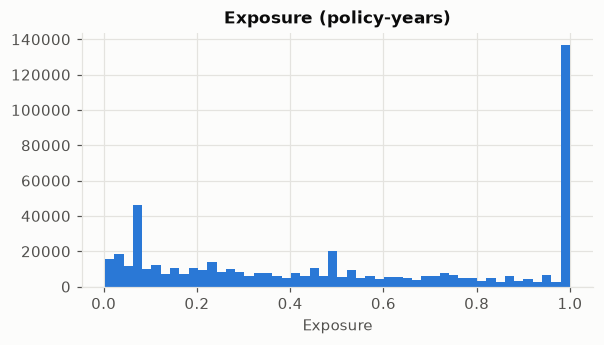

In [2]:
print(tr.ClaimNb.value_counts().sort_index())
print('portfolio frequency', tr.ClaimNb.sum() / tr.Exposure.sum())
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(tr.Exposure, bins=50, color=COLORS['GLM']); ax.set(title='Exposure (policy-years)', xlabel='Exposure')

## Marginal observed frequency by rating factor

The shapes motivate the GLM binning (young drivers, the bonus-malus slope, new vehicles).

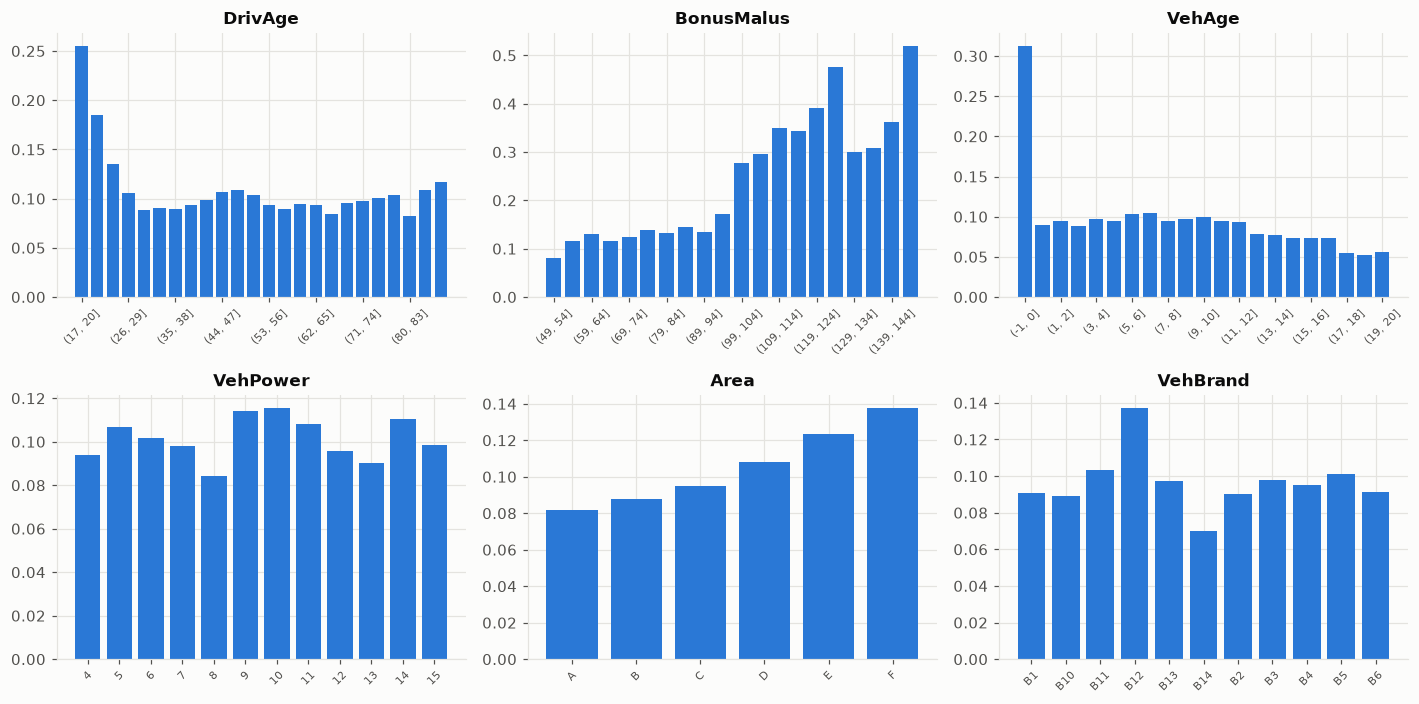

In [3]:
def freq_by(col, bins=None):
    g = tr.groupby(pd.cut(tr[col], bins) if bins is not None else tr[col], observed=True)
    return (g.ClaimNb.sum() / g.Exposure.sum()).rename('frequency').to_frame().assign(exposure=g.Exposure.sum())
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (col, bins) in zip(axes.flat, [('DrivAge', range(17, 92, 3)), ('BonusMalus', range(49, 152, 5)), ('VehAge', range(-1, 21)),
                                        ('VehPower', None), ('Area', None), ('VehBrand', None)]):
    f = freq_by(col, bins)
    ax.bar(range(len(f)), f.frequency, color=COLORS['GLM'], width=0.8)
    ax.set_xticks(range(len(f))[::max(1, len(f)//8)]); ax.set_xticklabels([str(i) for i in f.index][::max(1, len(f)//8)], rotation=45, fontsize=7)
    ax.set_title(col)
fig.tight_layout()

## Short exposures have higher claim frequency

A known quirk of this dataset (e.g. policies cancelled after a claim): frequency is not proportional to exposure, which the offset assumes. This shows up in the failure analysis.

In [4]:
freq_by('Exposure', [0, .05, .1, .25, .5, .75, .99, 1.0])

,frequency,exposure
Exposure,,
"(0.0, 0.05]",1.083971,1095.047474
"(0.05, 0.1]",0.319860,4927.150000
"(0.1, 0.25]",0.208909,13958.230000
"(0.25, 0.5]",0.125359,41114.010000
"(0.5, 0.75]",0.101777,46857.540000
"(0.75, 0.99]",0.086992,43164.910000
"(0.99, 1.0]",0.070060,135540.000000


## Severity

count    2.115800e+04
mean     2.062467e+03
std      1.256129e+04
min      1.000000e+00
50%      1.172000e+03
90%      2.771244e+03
99%      1.655055e+04
99.5%    3.414845e+04
max      1.301173e+06
Name: ClaimAmountRaw, dtype: float64


[Text(0.5, 1.0, 'log10 claim amount (train, uncapped)')]

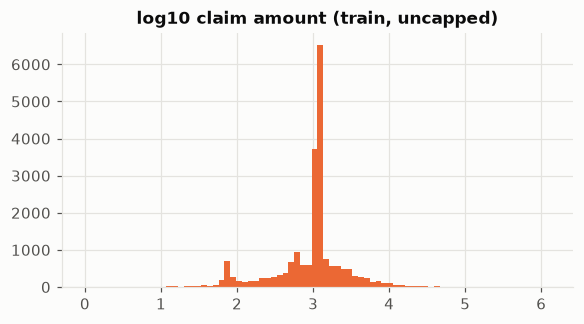

In [5]:
cl = pd.read_parquet('../data/processed/claims.parquet'); ct = cl[cl.split == 'train']
print(ct.ClaimAmountRaw.describe(percentiles=[.5, .9, .99, .995]))
fig, ax = plt.subplots(figsize=(6, 3)); ax.hist(np.log10(ct.ClaimAmountRaw), bins=80, color=COLORS['CANN']); ax.set(title='log10 claim amount (train, uncapped)')

## Repeated risk profiles

Many policies share every rating factor with another policy (likely the same insured re-issued under a new IDpol). Under a random split these twins land on both sides, which favours models that can memorise. `split_grouped` keeps twins together (experiment I7).

In [6]:
from src.data.schema import FEATURES
gid = pol.groupby(FEATURES, observed=True).ngroup()
size = gid.map(gid.value_counts())
print('unique profiles', gid.nunique(), 'of', len(pol), '| rows with a twin:', round((size > 1).mean(), 3))
print(pd.crosstab(pol.split, pol.split_grouped))

unique profiles 528641 of 678013 | rows with a twin: 0.381
split_grouped   test   train    val
split                              
test            6765   54229   6808
train          54263  434053  54094
val             6724   54136   6941
